In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

SEED = 42

In [3]:
iris = load_iris()
X = iris.data
y = iris.target

flowers = pd.DataFrame(X, columns=iris.feature_names)
flowers["species"] = iris.target_names[y]

print("First five flowers:")
print(flowers.head())
print("\nTotal flowers:", len(X))
print("Missing measurements:", np.isnan(X).sum())
print("Species:", iris.target_names)

First five flowers:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Total flowers: 150
Missing measurements: 0
Species: ['setosa' 'versicolor' 'virginica']


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=SEED
)

print("\nTraining flowers:", len(X_train))
print("Testing flowers:", len(X_test))


Training flowers: 120
Testing flowers: 30


In [6]:
def evaluate_predictions(actual, predicted):
    accuracy = accuracy_score(actual, predicted)
    f1 = f1_score(
        actual, predicted,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )
    return accuracy, f1

In [7]:
rng = np.random.default_rng(SEED)
number_of_flowers = len(X_train)
all_indices = np.arange(number_of_flowers)

sample_indices = rng.choice(
    all_indices,
    size=number_of_flowers,
    replace=True
)

unique_indices = np.unique(sample_indices)
oob_indices = np.setdiff1d(all_indices, unique_indices)

print("\nBOOTSTRAPPING")
print("Total draws:", len(sample_indices))
print("Different flowers selected:", len(unique_indices))
print("Out-of-bag flowers:", len(oob_indices))


BOOTSTRAPPING
Total draws: 120
Different flowers selected: 79
Out-of-bag flowers: 41


In [8]:
rng = np.random.default_rng(SEED)
bootstrap_accuracy = []
bootstrap_f1 = []

for repetition in range(100):
    sample_indices = rng.choice(
        all_indices,
        size=number_of_flowers,
        replace=True
    )

    oob_indices = np.setdiff1d(
        all_indices,
        np.unique(sample_indices)
    )

    if len(oob_indices) == 0:
        continue

    model = DecisionTreeClassifier(
        max_depth=3,
        random_state=SEED
    )

    model.fit(
        X_train[sample_indices],
        y_train[sample_indices]
    )

    predictions = model.predict(X_train[oob_indices])

    accuracy, f1 = evaluate_predictions(
        y_train[oob_indices], predictions
    )

    bootstrap_accuracy.append(accuracy)
    bootstrap_f1.append(f1)

print("\nBootstrap repetitions:", len(bootstrap_accuracy))
print("Mean accuracy:", round(np.mean(bootstrap_accuracy), 4))
print("Mean macro F1:", round(np.mean(bootstrap_f1), 4))




Bootstrap repetitions: 100
Mean accuracy: 0.9441
Mean macro F1: 0.9426


In [9]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

cv_accuracy = []
cv_f1 = []

for fold, (fit_indices, validation_indices) in enumerate(
    cv.split(X_train, y_train), start=1
):
    model = DecisionTreeClassifier(
        max_depth=3,
        random_state=SEED
    )

    model.fit(
        X_train[fit_indices],
        y_train[fit_indices]
    )

    predictions = model.predict(X_train[validation_indices])

    accuracy, f1 = evaluate_predictions(
        y_train[validation_indices], predictions
    )

    cv_accuracy.append(accuracy)
    cv_f1.append(f1)

    print(
        f"Fold {fold}: Accuracy = {accuracy:.4f}, "
        f"Macro F1 = {f1:.4f}"
    )

Fold 1: Accuracy = 0.9583, Macro F1 = 0.9582
Fold 2: Accuracy = 1.0000, Macro F1 = 1.0000
Fold 3: Accuracy = 0.9583, Macro F1 = 0.9582
Fold 4: Accuracy = 0.9583, Macro F1 = 0.9582
Fold 5: Accuracy = 0.9167, Macro F1 = 0.9153



RESAMPLING COMPARISON
       Method  Mean accuracy  Accuracy SD  Mean macro F1  Macro F1 SD
Bootstrap OOB         0.9441       0.0330         0.9426       0.0337
    5-fold CV         0.9583       0.0295         0.9580       0.0299


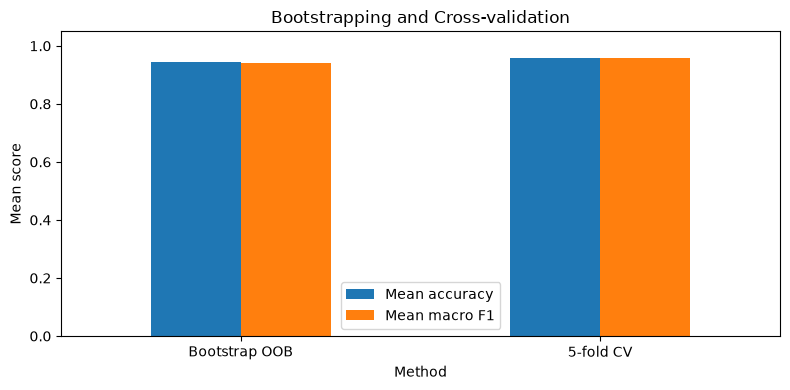

In [10]:
resampling_table = pd.DataFrame({
    "Method": ["Bootstrap OOB", "5-fold CV"],
    "Mean accuracy": [
        np.mean(bootstrap_accuracy),
        np.mean(cv_accuracy)
    ],
    "Accuracy SD": [
        np.std(bootstrap_accuracy, ddof=1),
        np.std(cv_accuracy, ddof=1)
    ],
    "Mean macro F1": [
        np.mean(bootstrap_f1),
        np.mean(cv_f1)
    ],
    "Macro F1 SD": [
        np.std(bootstrap_f1, ddof=1),
        np.std(cv_f1, ddof=1)
    ]
})

print("\nRESAMPLING COMPARISON")
print(resampling_table.round(4).to_string(index=False))

resampling_table.plot(
    x="Method",
    y=["Mean accuracy", "Mean macro F1"],
    kind="bar",
    ylim=(0, 1.05),
    rot=0,
    figsize=(8, 4)
)
plt.ylabel("Mean score")
plt.title("Bootstrapping and Cross-validation")
plt.tight_layout()
plt.show()



DECISION TREE DEPTH
Best depth: 3
 Depth  Training error  Validation error
     1          0.3333            0.3333
     2          0.0333            0.0583
     3          0.0208            0.0417
     4          0.0062            0.0583
     5          0.0021            0.0500
     6          0.0000            0.0500
     7          0.0000            0.0500
     8          0.0000            0.0500
     9          0.0000            0.0500
    10          0.0000            0.0500


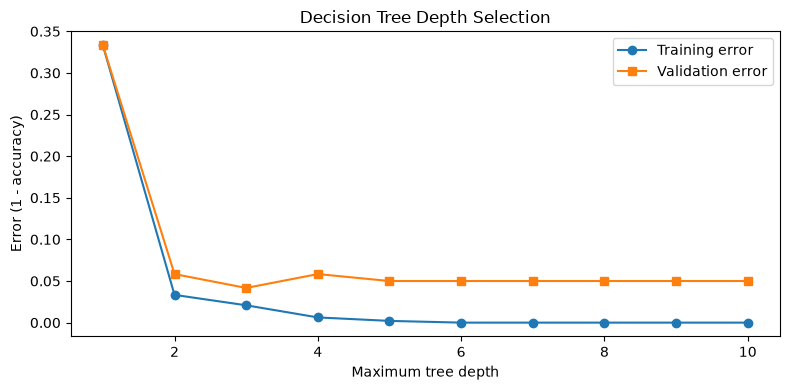

In [11]:
depths = range(1, 11)
training_errors = []
validation_errors = []

for depth in depths:
    fold_training_errors = []
    fold_validation_errors = []

    for fit_indices, validation_indices in cv.split(
        X_train, y_train
    ):
        model = DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED
        )

        model.fit(
            X_train[fit_indices],
            y_train[fit_indices]
        )

        train_predictions = model.predict(X_train[fit_indices])
        validation_predictions = model.predict(
            X_train[validation_indices]
        )

        train_error = 1 - accuracy_score(
            y_train[fit_indices], train_predictions
        )

        validation_error = 1 - accuracy_score(
            y_train[validation_indices], validation_predictions
        )

        fold_training_errors.append(train_error)
        fold_validation_errors.append(validation_error)

    training_errors.append(np.mean(fold_training_errors))
    validation_errors.append(np.mean(fold_validation_errors))

best_depth = list(depths)[np.argmin(validation_errors)]

print("\nDECISION TREE DEPTH")
print("Best depth:", best_depth)

depth_table = pd.DataFrame({
    "Depth": list(depths),
    "Training error": training_errors,
    "Validation error": validation_errors
})

print(depth_table.round(4).to_string(index=False))

plt.figure(figsize=(8, 4))
plt.plot(list(depths), training_errors, marker="o",
         label="Training error")
plt.plot(list(depths), validation_errors, marker="s",
         label="Validation error")
plt.xlabel("Maximum tree depth")
plt.ylabel("Error (1 - accuracy)")
plt.title("Decision Tree Depth Selection")
plt.legend()
plt.tight_layout()
plt.show()


In [12]:
single_tree = DecisionTreeClassifier(random_state=SEED)

bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=SEED),
    n_estimators=100,
    random_state=SEED
)

boosting = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=SEED
    ),
    n_estimators=100,
    learning_rate=0.5,
    random_state=SEED
)

selected_tree = DecisionTreeClassifier(
    max_depth=best_depth,
    random_state=SEED
)

single_tree.fit(X_train, y_train)
bagging.fit(X_train, y_train)
boosting.fit(X_train, y_train)
selected_tree.fit(X_train, y_train)

print("\nAll four models have been trained.")



All four models have been trained.



FINAL TEST RESULTS
           Model  Accuracy  Precision  Recall  Macro F1
     Single tree    0.9333     0.9333  0.9333    0.9333
         Bagging    0.9667     0.9697  0.9667    0.9666
        AdaBoost    0.9667     0.9697  0.9667    0.9666
CV-selected tree    0.9667     0.9697  0.9667    0.9666


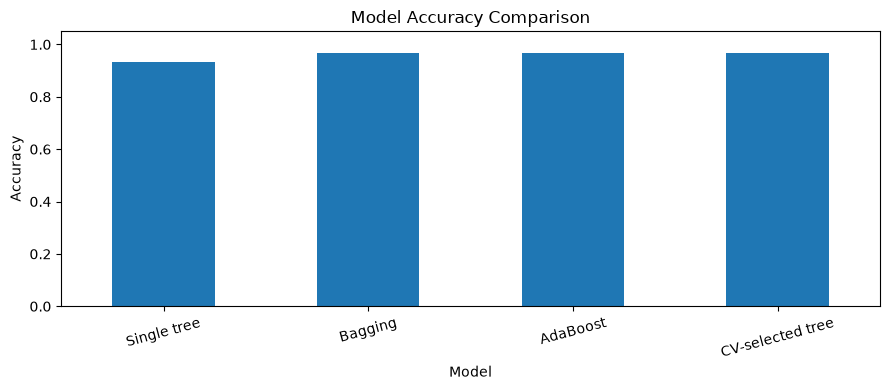


PRACTICAL COMPLETED SUCCESSFULLY


In [13]:
model_names = [
    "Single tree",
    "Bagging",
    "AdaBoost",
    "CV-selected tree"
]

trained_models = [
    single_tree,
    bagging,
    boosting,
    selected_tree
]

results = []

for name, model in zip(model_names, trained_models):
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions, average="macro", zero_division=0
    )
    recall = recall_score(
        y_test, predictions, average="macro", zero_division=0
    )
    f1 = f1_score(
        y_test, predictions, average="macro", zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Macro F1": f1
    })

results_table = pd.DataFrame(results)

print("\nFINAL TEST RESULTS")
print(results_table.round(4).to_string(index=False))

results_table.plot(
    x="Model",
    y="Accuracy",
    kind="bar",
    ylim=(0, 1.05),
    rot=15,
    figsize=(9, 4),
    legend=False
)
plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")
plt.tight_layout()
plt.show()

print("\nPRACTICAL COMPLETED SUCCESSFULLY")
